# Hammoud fibroblast subtype centroids mapped onto our human snRNA-seq data

Maps the centroids of all six **fibroblast** subtypes from Ulrich et al. (Hammoud lab,
PNAS 2024) onto our human fibroblast/decidual nuclei, to address two reviewer points:

1. **Do our data recapitulate familiar biology?** — the correspondence table below reports,
   for every Hammoud fibroblast subtype, whether we have a confident counterpart, and says
   so explicitly when we do not.
2. **You only sequenced two humans.** — every assignment is recomputed independently in
   each of the six sections, so the claim rests on replication rather than on pooled depth.

### Method and why

The primary statistic is a **cluster-level centroid comparison**, which is the method
Hammoud et al. themselves used to reconcile annotations across studies (their Fig. 3A is a
39×39 centroid rank-correlation matrix).

Two deliberate choices:

- **Cluster centroids, not per-cell correlation.** A median nucleus here has ~584 non-zero
  entries on the 3,000-gene discriminative panel (19.5%), with a 2× spread between the 5th
  and 95th percentile. A per-cell correlation against a dense atlas centroid would be
  computed ~80% against structural zeros and would substantially track library depth.
- **Double-centered ("contrastive") cosine as the headline.** Our data are single-*nucleus*
  and theirs are single-*cell*, so raw correlation carries a systematic dataset-level offset,
  and all fibroblast populations correlate at ~0.9 regardless. Centering each gene across
  the compared subtypes removes the offset and isolates relative pattern. Raw Spearman is
  reported alongside for continuity with their Fig. 3A.

No kNN expression smoothing is used anywhere. The per-cell layer at the end is a
depth-corrected **marker-set score**, which is honest about being a program score rather
than a per-cell identity call.

> Heavy steps (loading the object, clustering, the robustness battery) run in
> `run_mapping.py`. This notebook reads what that cached and renders it.

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

HAM = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud")
OUT = HAM / "fib_centroid_results"
sys.path.insert(0, str(HAM / "fib_mapping"))

from hammoud_fib_mapping import FIB_SUBTYPES, SHORT, load_atlas_centroids, load_atlas_markers

cfg = dict(l.strip().split("=", 1) for l in open(OUT / "run_config.txt") if "=" in l)
CLUSTER_KEY = cfg["cluster_key"]
print(cfg)

{'resolution': '0.5', 'cluster_key': 'leiden_0.5', 'n_panel': '3000', 'min_cluster_n': '100', 'n_boot': '500', 'seed': '0', 'n_obs': '47533', 'n_shared_genes': '33791'}


In [2]:
atlas = load_atlas_centroids(HAM / "pnas.2404775121.sd05.xlsx")
STRO = [c for c in atlas.columns if c.startswith("Stro-")]

read = lambda name, **kw: pd.read_csv(OUT / name, **kw)
M_cos = read("similarity_fib_contrastive_cosine.csv", index_col=0)
M_spr = read("similarity_fib_spearman.csv", index_col=0)
M_stro = read("similarity_stro_contrastive_cosine.csv", index_col=0)
by_cluster = read("correspondence_fib_by_cluster.csv", index_col=0)
by_subtype = read("correspondence_fib_by_subtype.csv", index_col=0)
by_subtype_spr = read("correspondence_fib_by_subtype_spearman.csv", index_col=0)
by_subtype_stro = read("correspondence_stro_by_subtype.csv", index_col=0)
sizes = read("cluster_sizes.csv", index_col=0).iloc[:, 0]

sweep = read("resolution_sweep.csv")
per_sample = read("replication_per_sample.csv")
per_phase = read("replication_per_phase.csv")
consistency = read("replication_consistency.csv")
abl = read("robustness_marker_ablation.csv")
boot = read("robustness_gene_bootstrap.csv")
held = read("robustness_heldout_split.csv")
marker_sets = read("marker_sets.csv")
score_by_cluster = read("score_by_cluster.csv", index_col=0)
frac_pos = read("headline_marker_fraction_positive.csv", index_col=0)

M_cos.columns = [c for c in M_cos.columns]
print(f"{M_cos.shape[0]} query clusters x {M_cos.shape[1]} fibroblast subtypes")

6 query clusters x 6 fibroblast subtypes


## 1. Choice of clustering resolution

Our human object ships with no fibroblast subclustering (`subtype` and `fine_refined` are
empty; only `cell_type` distinguishes fibroblast from decidual), so clusters are computed
here.

Resolution is **set deliberately to 0.5**, not auto-selected. The obvious rule — maximise
the number of reciprocal matches — picks 2.0, but for the wrong reason: the extra "match"
is Stro-5 at a score of 0.08, which is noise, while every real margin collapses as 6
clusters become 22 (Stro-10 goes from 0.17 to 0.007, and held-out validation for Stro-7
falls from 1.00 to 0.44 because the 22 clusters split one population into near-identical
siblings the test then has to choose between).

Nothing important rests on this choice: `resolution_stability.py` recomputes the entire
mapping at every resolution from 0.3 to 2.0 and the Stro-7 correspondence is reciprocal at
all of them, with the largest margin at each.

In [3]:
display(sweep.round(3))
print("chosen:", CLUSTER_KEY)

,resolution,n_clusters,n_clusters_kept,n_distinct_matches,n_subtypes_reciprocal,median_margin,smallest_cluster
0,0.3,2,2,2,2,0.201,12455
1,0.5,6,6,3,3,0.047,791
2,0.8,6,6,3,3,0.045,814
3,1.2,12,10,3,3,0.025,866
4,2.0,22,21,4,4,0.021,107


chosen: leiden_0.5


## 2. Primary result — correspondence matrix

Rows are our clusters, columns are the six Hammoud fibroblast subtypes. Cells outlined in
black are **reciprocal best matches**: the cluster's top subtype is that subtype, and that
subtype's top cluster is that cluster.

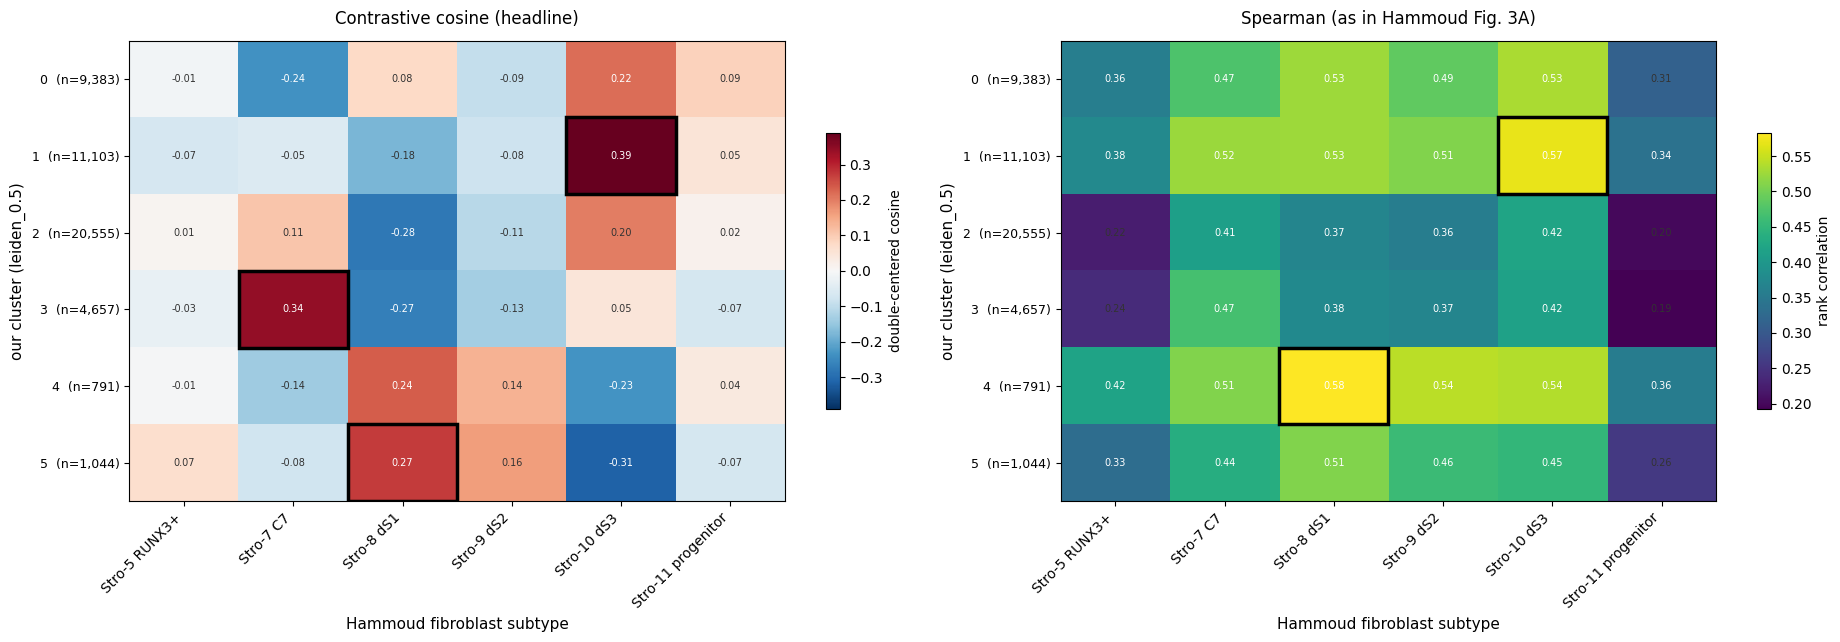

In [4]:
def corr_heatmap(M, by_a, title, cbar_label, cmap="RdBu_r", center=True, ax=None,
                 annot=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(1.1 * M.shape[1] + 4, 0.42 * M.shape[0] + 3))
    v = np.nanmax(np.abs(M.to_numpy())) if center else None
    kw = dict(vmin=-v, vmax=v) if center else {}
    im = ax.imshow(M.to_numpy(), aspect="auto", cmap=cmap, **kw)

    ax.set_xticks(range(M.shape[1]))
    ax.set_xticklabels([SHORT.get(c, c) for c in M.columns], rotation=45,
                       ha="right", fontsize=10)
    ax.set_yticks(range(M.shape[0]))
    ax.set_yticklabels([f"{i}  (n={int(sizes.get(i, 0)):,})" for i in M.index], fontsize=9)

    recip = {(by_a.loc[s, "best_query"], s) for s in by_a.index if by_a.loc[s, "reciprocal"]}
    for i, q in enumerate(M.index):
        for j, s in enumerate(M.columns):
            if annot:
                val = M.iloc[i, j]
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if abs(val) > 0.55 * np.nanmax(np.abs(M.to_numpy())) else "0.2")
            if (str(q), s) in {(str(a), b) for a, b in recip}:
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False,
                                           edgecolor="black", lw=2.5))
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xlabel("Hammoud fibroblast subtype", fontsize=11)
    ax.set_ylabel(f"our cluster ({CLUSTER_KEY})", fontsize=11)
    plt.colorbar(im, ax=ax, shrink=0.6, label=cbar_label)
    return ax

fig, axes = plt.subplots(1, 2, figsize=(19, 0.42 * M_cos.shape[0] + 4))
corr_heatmap(M_cos, by_subtype, "Contrastive cosine (headline)",
             "double-centered cosine", ax=axes[0])
corr_heatmap(M_spr, by_subtype_spr, "Spearman (as in Hammoud Fig. 3A)",
             "rank correlation", center=False, cmap="viridis", ax=axes[1])
plt.tight_layout()
plt.savefig(OUT / "fig1_correspondence_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

### The correspondence table

This is the table for the rebuttal. One row per Hammoud fibroblast subtype, including the
ones we cannot claim.

In [5]:
# Calibrate "how good is a good score?" on the five subtypes that cannot have a
# counterpart here (perivascular, vascular progenitor, uSMC), rather than on a
# threshold picked by hand.
NEG_CONTROLS = ["Stro-1_PV MYH11 FOXC1hi CTGFlo", "Stro-2_PV MYH11 FOXC1lo CTGFhi",
                "Stro-3_PV STEAP4", "Stro-4_Tissue resident vascular progenitor",
                "Stro-6_uSMC"]
NEG_CEILING = by_subtype_stro.loc[NEG_CONTROLS, "score"].max()
print(f"negative-control score band: "
      f"{by_subtype_stro.loc[NEG_CONTROLS, 'score'].min():.3f} - {NEG_CEILING:.3f}")
print(f"any of them reciprocal? {by_subtype_stro.loc[NEG_CONTROLS, 'reciprocal'].any()}")

tbl = by_subtype.copy()
tbl["bootstrap_freq"] = boot.set_index("subtype")["frequency"].reindex(tbl.index).values
tbl["heldout_agreement"] = held.set_index("subtype")["validation_agreement"].reindex(tbl.index).values
tbl["sample_agreement"] = consistency.set_index("subtype")["agreement"].reindex(tbl.index).values
tbl["spearman_best"] = by_subtype_spr["best_query"].reindex(tbl.index).values
tbl["above_neg_controls"] = tbl["score"] > NEG_CEILING

# A subtype whose best cluster is already some other subtype's reciprocal partner
# is present in our data but not separable from that neighbour.
owner = {r["best_query"]: s for s, r in tbl.iterrows() if r["reciprocal"]}

def call(r):
    if not r["above_neg_controls"]:
        return "no counterpart above negative controls"
    if not r["reciprocal"] and r["best_query"] in owner:
        return f"not resolved from {SHORT.get(owner[r['best_query']], owner[r['best_query']])}"
    if (r["reciprocal"] and r["bootstrap_freq"] >= .9
            and r["heldout_agreement"] >= .9 and r["sample_agreement"] >= .8):
        return "confident"
    if r["reciprocal"] and r["bootstrap_freq"] >= .7 and r["heldout_agreement"] >= .7:
        return "probable"
    return "one-directional"

tbl["call"] = [call(r) for _, r in tbl.iterrows()]
tbl.index = [SHORT.get(i, i) for i in tbl.index]
tbl = tbl[["best_query", "score", "margin", "above_neg_controls", "reciprocal",
           "bootstrap_freq", "heldout_agreement", "sample_agreement",
           "spearman_best", "n_in_best_query", "call"]]
tbl.to_csv(OUT / "TABLE_correspondence_summary.csv")
display(tbl.round(3))

negative-control score band: 0.081 - 0.124
any of them reciprocal? False


,best_query,score,margin,above_neg_controls,reciprocal,bootstrap_freq,heldout_agreement,sample_agreement,spearman_best,n_in_best_query,call
Stro-5 RUNX3+,5,0.065,0.055,False,False,1.000,0.024,0.5,4,1044,no counterpart above negative controls
Stro-7 C7,3,0.343,0.236,True,True,1.000,1.000,1.0,1,4657,confident
Stro-8 dS1,5,0.273,0.037,True,True,0.988,0.934,0.5,4,1044,probable
Stro-9 dS2,5,0.162,0.026,True,False,0.882,0.996,0.5,4,1044,not resolved from Stro-8 dS1
Stro-10 dS3,1,0.389,0.172,True,True,1.000,1.000,1.0,1,11103,confident
Stro-11 progenitor,0,0.089,0.040,False,False,0.994,1.000,1.0,4,9383,no counterpart above negative controls


**Why `spearman_best` mostly disagrees.** Raw rank correlation across the
single-nucleus/single-cell boundary is dominated by the shared fibroblast program: every
score lands in a narrow 0.36–0.58 band with margins under 0.06, so the argmax drifts to
whichever cluster is largest and most "average" rather than the correct subtype. That is
the concrete reason the double-centered cosine is the headline statistic here and the raw
correlation is shown only for continuity with the paper's Fig. 3A.

## 3. Sink test — are these matches real, or argmax with nowhere else to go?

Our object contains only fibroblasts and decidual cells, so the same mapping run against
**all eleven** stromal subtypes should leave the perivascular (Stro-1/2/3), vascular
progenitor (Stro-4) and uSMC (Stro-6) columns without a good partner. If those columns
capture clusters strongly, the fibroblast-only mapping was forcing assignments.

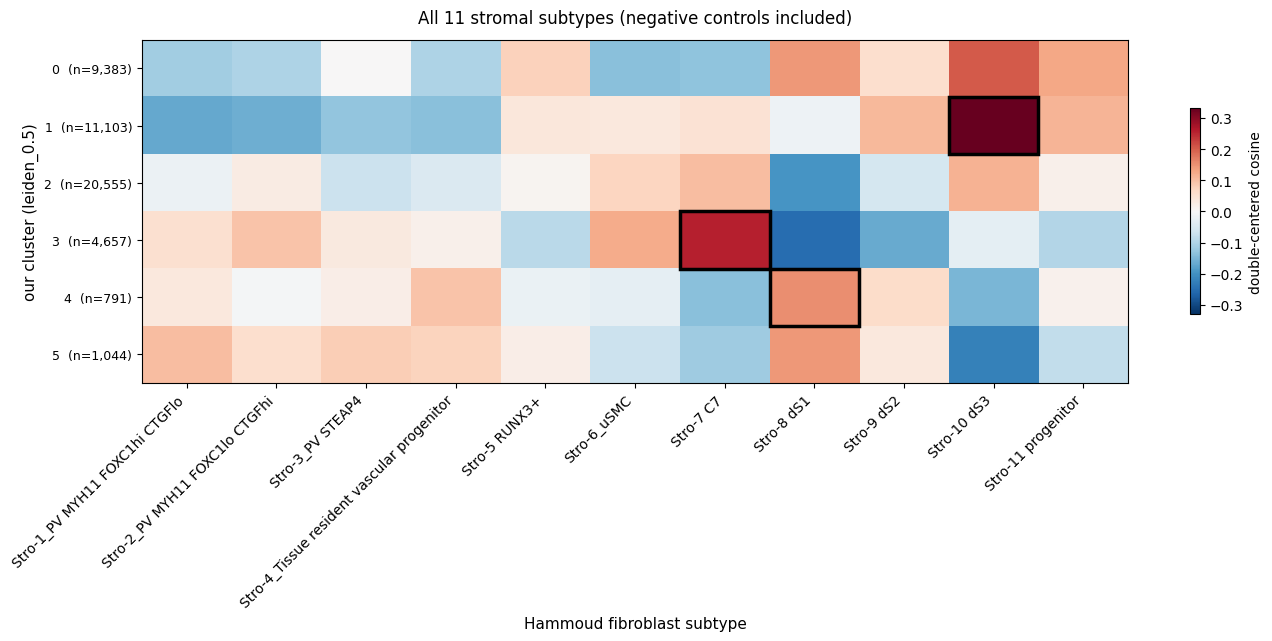

,best_query,score,margin,reciprocal,n_in_best_query,is_negative_control
Stro-10_dS3,1,0.330,0.128,True,11103,False
Stro-7_C7 Fibroblast,3,0.258,0.156,True,4657,False
Stro-8_dS1,4,0.154,0.009,True,791,False
Stro-11_Stromal progenitor,0,0.129,0.015,False,9383,False
Stro-9_dS2,1,0.108,0.047,False,11103,False
Stro-5_RUNX3+ Fibroblast,0,0.076,0.038,False,9383,False
Stro-6_uSMC,3,0.124,0.052,False,4657,True
Stro-1_PV MYH11 FOXC1hi CTGFlo,5,0.101,0.049,False,1044,True
Stro-2_PV MYH11 FOXC1lo CTGFhi,3,0.095,0.040,False,4657,True
Stro-4_Tissue resident vascular progenitor,4,0.095,0.021,False,791,True


In [6]:
fig, ax = plt.subplots(figsize=(14, 0.42 * M_stro.shape[0] + 4))
corr_heatmap(M_stro, by_subtype_stro, "All 11 stromal subtypes (negative controls included)",
             "double-centered cosine", ax=ax, annot=False)
plt.tight_layout()
plt.savefig(OUT / "fig2_sink_test.png", dpi=200, bbox_inches="tight")
plt.show()

ctrl = ["Stro-1_PV MYH11 FOXC1hi CTGFlo", "Stro-2_PV MYH11 FOXC1lo CTGFhi",
        "Stro-3_PV STEAP4", "Stro-4_Tissue resident vascular progenitor", "Stro-6_uSMC"]
summary = by_subtype_stro.copy()
summary["is_negative_control"] = summary.index.isin(ctrl)
display(summary.sort_values(["is_negative_control", "score"], ascending=[True, False]).round(3))

## 4. Replication across sections and phases

The mapping is recomputed from scratch inside each section. This is the answer to "you only
sequenced two humans": the assignments come back independently in six sections.

**Caveat to state in the rebuttal:** the two donors are `mck5` (menstrual) and `mck6`
(secretory), so donor and cycle phase are perfectly confounded in this design. A subtype
that replicates in all six sections replicates across both donors and both phases; one that
splits 3/3 may be tracking phase rather than failing to replicate.

sample,menstrual_mck5a,menstrual_mck5b,menstrual_mck5c,secretory_mck6a,secretory_mck6b,secretory_mck6c
Stro-10 dS3,1,1,1,1,1,1
Stro-11 progenitor,0,0,0,0,0,0
Stro-5 RUNX3+,5,5,5,2,0,2
Stro-7 C7,3,3,3,3,3,3
Stro-8 dS1,5,5,5,0,0,0
Stro-9 dS2,5,5,5,1,1,1


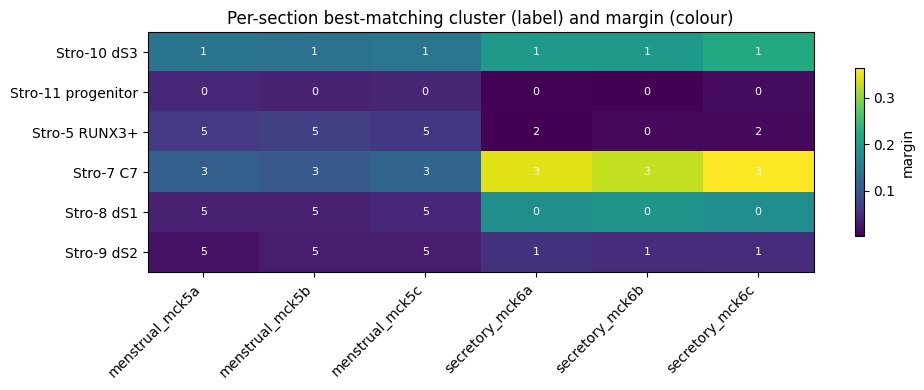

,subtype,modal,agreement,n_samples
0,Stro-10_dS3,1,1.0,6
1,Stro-11_Stromal progenitor,0,1.0,6
2,Stro-5_RUNX3+ Fibroblast,5,0.5,6
3,Stro-7_C7 Fibroblast,3,1.0,6
4,Stro-8_dS1,5,0.5,6
5,Stro-9_dS2,5,0.5,6


,timepoint,subtype,best_query,score,margin,n_in_best_query
0,menstrual,Stro-5_RUNX3+ Fibroblast,5,0.070,0.068,1038
1,menstrual,Stro-7_C7 Fibroblast,3,0.287,0.112,1933
2,menstrual,Stro-8_dS1,5,0.277,0.036,1038
3,menstrual,Stro-9_dS2,5,0.165,0.025,1038
4,menstrual,Stro-10_dS3,1,0.365,0.142,7819
5,menstrual,Stro-11_Stromal progenitor,0,0.085,0.043,7487
6,secretory,Stro-5_RUNX3+ Fibroblast,0,0.034,0.000,1896
7,secretory,Stro-7_C7 Fibroblast,3,0.432,0.349,2724
8,secretory,Stro-8_dS1,0,0.223,0.184,1896
9,secretory,Stro-9_dS2,1,0.051,0.052,3284


In [7]:
pivot = per_sample.pivot(index="subtype", columns="sample", values="best_query")
pivot.index = [SHORT.get(i, i) for i in pivot.index]
display(pivot)

fig, ax = plt.subplots(figsize=(10, 4))
w = per_sample.pivot(index="subtype", columns="sample", values="margin")
w.index = [SHORT.get(i, i) for i in w.index]
im = ax.imshow(w.to_numpy(), aspect="auto", cmap="viridis")
ax.set_xticks(range(w.shape[1])); ax.set_xticklabels(w.columns, rotation=45, ha="right")
ax.set_yticks(range(w.shape[0])); ax.set_yticklabels(w.index)
for i in range(w.shape[0]):
    for j in range(w.shape[1]):
        ax.text(j, i, pivot.iloc[i, j], ha="center", va="center", fontsize=8, color="w")
ax.set_title("Per-section best-matching cluster (label) and margin (colour)")
plt.colorbar(im, ax=ax, shrink=.7, label="margin")
plt.tight_layout()
plt.savefig(OUT / "fig3_replication.png", dpi=200, bbox_inches="tight")
plt.show()

display(consistency.round(3))
display(per_phase.round(3))

## 5. Robustness

Three checks, each run for all six subtypes. All of them resample *genes*, and since
`log1p(mean(expm1(x)))` is per-gene independent, they are row-indexing on the cached
centroid matrix rather than repeated passes over the counts.

- **Marker ablation** — progressively delete each subtype's most specific genes. A match
  that survives is not driven by a handful of headline markers.
- **Gene bootstrap** — 500 random 70% gene subsets; how often the same cluster wins.
- **Held-out split** — pick the cluster on discovery genes, test it on genes that played no
  part in the selection.

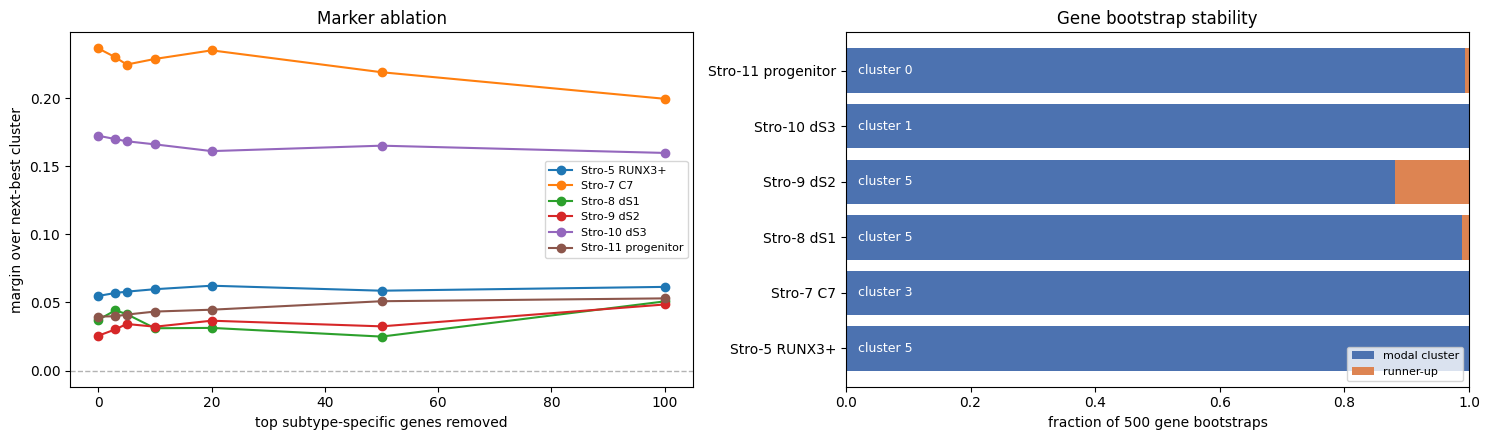

,subtype,modal_query,frequency,runner_up,runner_up_freq,mean_score,sd_score
0,Stro-5_RUNX3+ Fibroblast,5,1.000,NaN,0.000,0.066,0.011
1,Stro-7_C7 Fibroblast,3,1.000,NaN,0.000,0.343,0.016
2,Stro-8_dS1,5,0.988,4.0,0.012,0.273,0.014
3,Stro-9_dS2,5,0.882,4.0,0.118,0.163,0.018
4,Stro-10_dS3,1,1.000,NaN,0.000,0.389,0.013
5,Stro-11_Stromal progenitor,0,0.994,1.0,0.006,0.089,0.012


,subtype,validation_agreement,median_validation_margin,n_rep
0,Stro-5_RUNX3+ Fibroblast,0.024,0.028,500
1,Stro-7_C7 Fibroblast,1.000,0.265,500
2,Stro-8_dS1,0.934,0.109,500
3,Stro-9_dS2,0.996,0.184,500
4,Stro-10_dS3,1.000,0.195,500
5,Stro-11_Stromal progenitor,1.000,0.437,500


,subtype,n_removed,best_query,score,margin
0,Stro-5_RUNX3+ Fibroblast,0,5,0.065,0.055
1,Stro-5_RUNX3+ Fibroblast,3,5,0.068,0.057
2,Stro-5_RUNX3+ Fibroblast,5,5,0.069,0.058
3,Stro-5_RUNX3+ Fibroblast,10,5,0.072,0.060
4,Stro-5_RUNX3+ Fibroblast,20,5,0.074,0.062
5,Stro-5_RUNX3+ Fibroblast,50,5,0.075,0.059
6,Stro-5_RUNX3+ Fibroblast,100,5,0.082,0.061
7,Stro-7_C7 Fibroblast,0,3,0.343,0.236
8,Stro-7_C7 Fibroblast,3,3,0.336,0.230
9,Stro-7_C7 Fibroblast,5,3,0.332,0.225


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

for s in FIB_SUBTYPES:
    d = abl[abl.subtype == s]
    axes[0].plot(d.n_removed, d.margin, marker="o", label=SHORT.get(s, s))
axes[0].set_xlabel("top subtype-specific genes removed")
axes[0].set_ylabel("margin over next-best cluster")
axes[0].set_title("Marker ablation")
axes[0].axhline(0, color="0.7", lw=1, ls="--")
axes[0].legend(fontsize=8)

b = boot.set_index("subtype").reindex(FIB_SUBTYPES)
y = np.arange(len(b))
axes[1].barh(y, b.frequency, color="#4C72B0", label="modal cluster")
axes[1].barh(y, b.runner_up_freq, left=b.frequency, color="#DD8452", label="runner-up")
axes[1].set_yticks(y); axes[1].set_yticklabels([SHORT.get(i, i) for i in b.index])
for i, (f, m) in enumerate(zip(b.frequency, b.modal_query)):
    axes[1].text(0.02, i, f"cluster {m}", va="center", fontsize=9, color="white")
axes[1].set_xlabel("fraction of 500 gene bootstraps")
axes[1].set_title("Gene bootstrap stability")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(OUT / "fig4_robustness.png", dpi=200, bbox_inches="tight")
plt.show()

display(boot.round(3))
display(held.round(3))
display(abl.round(3))

## 6. Marker-level evidence

The centroid correlations *nominate* pairs; what actually carries a rebuttal is whether the
defining markers are expressed in both populations. Two marker sources are compared: genes
derived from the atlas centroids, and the paper's own published DE markers (Dataset S6C).
Their overlap is itself a check.

In [9]:
display(marker_sets[["subtype", "n_centroid_derived", "n_published_detected", "n_shared"]])
for _, r in marker_sets.iterrows():
    print(f"\n{SHORT.get(r.subtype, r.subtype)} — shared by both sources:")
    print("  " + (r.shared if isinstance(r.shared, str) and r.shared else "(none)"))

,subtype,n_centroid_derived,n_published_detected,n_shared
0,Stro-5_RUNX3+ Fibroblast,50,50,45
1,Stro-7_C7 Fibroblast,50,50,35
2,Stro-8_dS1,50,50,22
3,Stro-9_dS2,50,37,10
4,Stro-10_dS3,50,50,12
5,Stro-11_Stromal progenitor,50,50,44



Stro-5 RUNX3+ — shared by both sources:
  ALOX5AP, ANXA1, ARHGDIB, CCL3, CCL4, CCL5, CD2, CD37, CD3D, CD3E, CD52, CD69, CD7, CORO1A, CPA3, CST7, CTSW, CXCR4, FCER1G, GMFG, GNLY, GZMA, GZMB, HCST, IL2RB, IL32, KLRB1, LAPTM5, LCP1, LTB, NKG7, PTPRC, RAC2, RGS1, S100A10, SRGN, TPSAB1, TPSB2, TRAC, TRBC1, TRBC2, TRDC, TYROBP, XCL1, XCL2

Stro-7 C7 — shared by both sources:
  ADH1B, APOD, ASPN, C7, CCDC80, CST3, CTSK, CXCL12, DCN, DPT, FAP, FBLN1, FBLN5, GPNMB, GSN, HTRA1, IGFBP5, MATN2, MFAP4, MGP, OGN, OMD, PDGFRL, PLTP, PLXDC2, PMP22, PODN, PRELP, RARRES2, SCN7A, SERPINF1, SPOCK1, SRPX, TIMP1, TNXB

Stro-8 dS1 — shared by both sources:
  APOC1, APOE, CXCL8, DKK1, ID2, ID3, ID4, MIR4435-2HG, NEAT1, NID1, PLIN2, PRDM1, RBP1, RND3, S100A6, SOD2, TGM2, TIMP3, TMEM45A, TMSB4X, TWISTNB, WTAP

Stro-9 dS2 — shared by both sources:
  DEFB1, FOSB, IER2, IER3, JUND, MTRNR2L12, PAEP, RASD1, SCGB1D4, ZBTB20

Stro-10 dS3 — shared by both sources:
  APCDD1, CD248, CDH11, COL1A1, COL3A1, COL5A2, GDF7, 

In [10]:
# Load the object once for the expression-level panels.
human = sc.read_h5ad("/n/netscratch/eddy_lab/Everyone/nhilgert/"
                     "2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad")
human.layers["log1p"] = human.X.copy()
assign = pd.read_csv(OUT / "cluster_assignments.csv", index_col=0)
for c in assign.columns:
    human.obs[c] = assign[c].reindex(human.obs_names).astype(str).values
print(human.obs[CLUSTER_KEY].value_counts().sort_index().to_dict())

{'0': 9383, '1': 11103, '2': 20555, '3': 4657, '4': 791, '5': 1044}


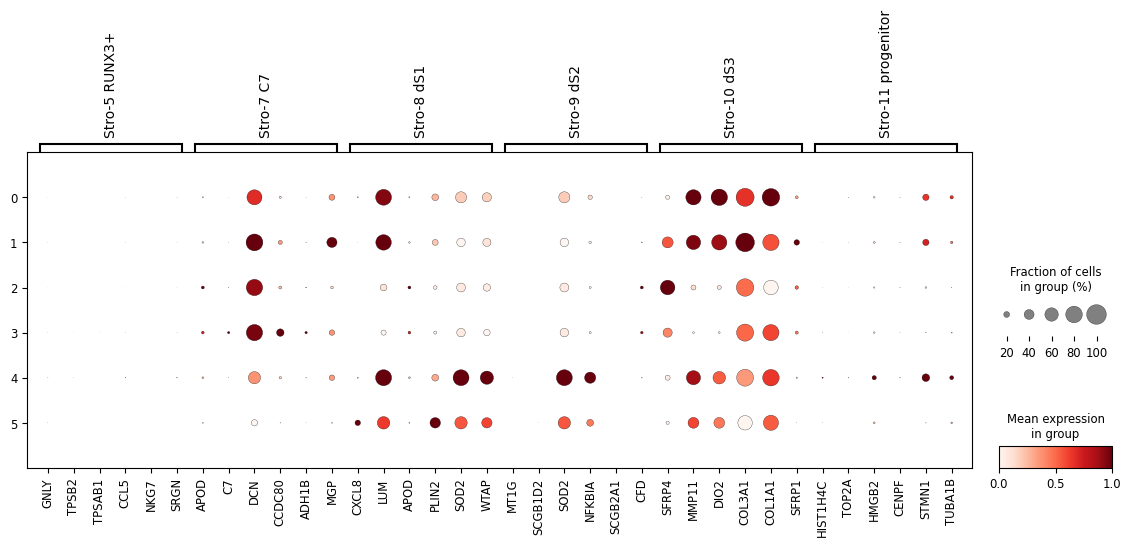

In [11]:
# Published S6C markers per subtype, top 6 each, across our clusters.
groups = {}
for _, r in marker_sets.iterrows():
    gs = [g for g in str(r.published_s6c).split(", ") if g in human.var_names][:6]
    if gs:
        groups[SHORT.get(r.subtype, r.subtype)] = gs

sc.pl.dotplot(human, groups, groupby=CLUSTER_KEY, layer="log1p", use_raw=False,
              standard_scale="var", figsize=(14, 0.35 * human.obs[CLUSTER_KEY].nunique() + 2),
              save="_fib_published_markers.png")

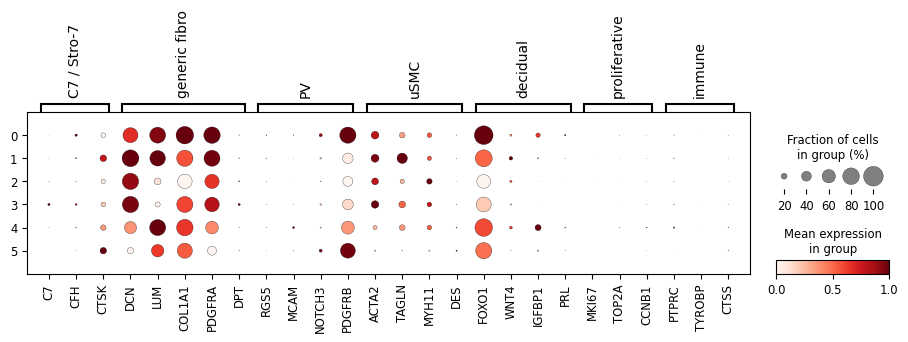

In [12]:
# Negative-control identities: the nominated clusters should not simply be PV, uSMC or immune.
controls = {
    "C7 / Stro-7": ["C7", "CFH", "CTSK"],
    "generic fibro": ["DCN", "LUM", "COL1A1", "PDGFRA", "DPT"],
    "PV": ["RGS5", "MCAM", "NOTCH3", "PDGFRB"],
    "uSMC": ["ACTA2", "TAGLN", "MYH11", "DES"],
    "decidual": ["FOXO1", "WNT4", "IGFBP1", "PRL"],
    "proliferative": ["MKI67", "TOP2A", "CCNB1"],
    "immune": ["PTPRC", "TYROBP", "CTSS"],
}
controls = {k: [g for g in v if g in human.var_names] for k, v in controls.items()}
sc.pl.dotplot(human, {k: v for k, v in controls.items() if v}, groupby=CLUSTER_KEY,
              layer="log1p", use_raw=False, standard_scale="var",
              save="_fib_negative_controls.png")

### Better marker panels, and why three subtypes cannot map

Ranking the published markers by fold-change alone surfaces generic ECM genes (DCN, LUM,
COL1A1) that are high in every fibroblast and so discriminate nothing. Filtering to genes
that are both **specific in the atlas** and **detectable in our nuclei** (>10% of cells)
gives panels that actually separate the clusters.

That filter also explains every non-match. Marker detectability tracks the calls almost
perfectly, and the three subtypes that fail are each defined by a program our object either
excludes by construction or measures differently — these are compositional and technical
facts, not shortcomings of the data.

In [13]:
det = read("marker_panel_detectability.csv")
det["call"] = det["subtype"].map(tbl["call"])
display(det.sort_values("mean_detection_rate", ascending=False).round(4))

PROGRAMS = {
    "cycling (defines Stro-11)": ["MKI67", "TOP2A", "CENPF", "UBE2C", "BIRC5", "CDK1"],
    "immune (defines Stro-5)": ["PTPRC", "GNLY", "NKG7", "CCL5", "TYROBP", "TPSAB1"],
    "immediate-early / stress (defines Stro-9)": ["FOSB", "JUND", "ATF3", "NR4A1", "IER2"],
    "C7 program (defines Stro-7)": ["C7", "CFH", "CTSK", "APOD", "CCDC80", "IGFBP5"],
    "decidual (defines Stro-8/9/10)": ["IGFBP1", "PRL", "FOXO1", "WNT4"],
}
import scipy.sparse as sps
rows = []
for name, gs in PROGRAMS.items():
    g = [x for x in gs if x in human.var_names]
    X = sps.csr_matrix(human[:, g].layers["log1p"])
    n_pos = np.asarray((X > 0).sum(axis=1)).ravel()
    rows.append({"program": name, "nuclei_positive_for_any": (n_pos > 0).mean(),
                 "genes": ", ".join(g)})
prog = pd.DataFrame(rows)
display(prog.round(4))
prog.to_csv(OUT / "program_detectability.csv", index=False)

,subtype,n_markers,n_in_object,mean_detection_rate,call
4,Stro-10 dS3,50,50,0.3603,confident
2,Stro-8 dS1,50,50,0.2656,probable
1,Stro-7 C7,50,50,0.2428,confident
3,Stro-9 dS2,37,37,0.1760,not resolved from Stro-8 dS1
5,Stro-11 progenitor,50,50,0.0556,no counterpart above negative controls
0,Stro-5 RUNX3+,50,50,0.0074,no counterpart above negative controls


,program,nuclei_positive_for_any,genes
0,cycling (defines Stro-11),0.0293,"MKI67, TOP2A, CENPF, UBE2C, BIRC5, CDK1"
1,immune (defines Stro-5),0.0098,"PTPRC, GNLY, NKG7, CCL5, TYROBP, TPSAB1"
2,immediate-early / stress (defines Stro-9),0.3841,"FOSB, JUND, ATF3, NR4A1, IER2"
3,C7 program (defines Stro-7),0.4853,"C7, CFH, CTSK, APOD, CCDC80, IGFBP5"
4,decidual (defines Stro-8/9/10),0.7600,"IGFBP1, PRL, FOXO1, WNT4"


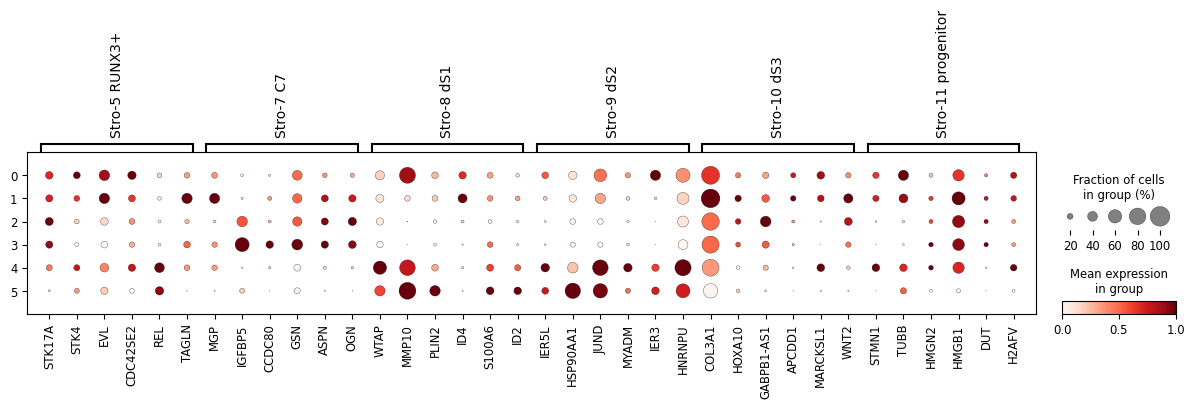

In [14]:
panels = read("marker_panels_detectable.csv")
groups2 = {r.subtype: [g for g in str(r.genes).split(", ") if g in human.var_names]
           for _, r in panels.iterrows()}
groups2 = {k: v for k, v in groups2.items() if v}
sc.pl.dotplot(human, groups2, groupby=CLUSTER_KEY, layer="log1p", use_raw=False,
              standard_scale="var", show=False)
plt.savefig(OUT / "fig7_detectable_markers_dotplot.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Per-cell layer and spatial readout

A depth-corrected marker-set score, computed with `score_genes` control-gene binning — no
kNN smoothing, so nothing is borrowed across sections and the score is not circular with
the scVI embedding it would otherwise be smoothed over.

Read this as a continuous program score, not a per-cell identity call.

,score_Stro-5,score_Stro-7,score_Stro-8,score_Stro-9,score_Stro-10,score_Stro-11
leiden_0.5,,,,,,
0,-0.010,0.196,0.503,0.305,0.623,-0.029
1,-0.012,0.293,0.489,0.240,0.675,-0.003
2,-0.011,0.217,0.251,0.219,0.428,-0.011
3,-0.003,0.354,0.225,0.198,0.313,-0.022
4,-0.010,0.134,0.535,0.390,0.422,0.024
5,0.004,0.124,0.518,0.448,0.424,-0.038


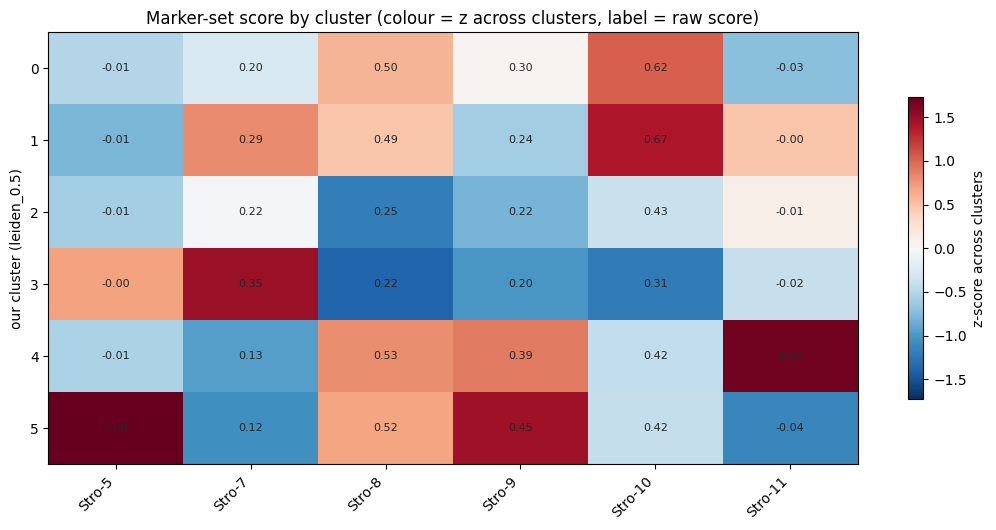

In [15]:
# Each subtype's marker score averaged per cluster. The nominated cluster should
# top its own subtype's column.
display(score_by_cluster.round(3))

fig, ax = plt.subplots(figsize=(1.3 * score_by_cluster.shape[1] + 3,
                                0.4 * score_by_cluster.shape[0] + 3))
z = score_by_cluster.sub(score_by_cluster.mean()).div(score_by_cluster.std().replace(0, np.nan))
im = ax.imshow(z.to_numpy(), aspect="auto", cmap="RdBu_r",
               vmin=-np.nanmax(np.abs(z.to_numpy())), vmax=np.nanmax(np.abs(z.to_numpy())))
ax.set_xticks(range(z.shape[1]))
ax.set_xticklabels([c.replace("score_", "") for c in z.columns], rotation=45, ha="right")
ax.set_yticks(range(z.shape[0])); ax.set_yticklabels(z.index)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{score_by_cluster.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=8, color="0.15")
ax.set_title("Marker-set score by cluster (colour = z across clusters, label = raw score)")
ax.set_ylabel(f"our cluster ({CLUSTER_KEY})")
plt.colorbar(im, ax=ax, shrink=.7, label="z-score across clusters")
plt.tight_layout()
plt.savefig(OUT / "fig6_marker_scores.png", dpi=200, bbox_inches="tight")
plt.show()

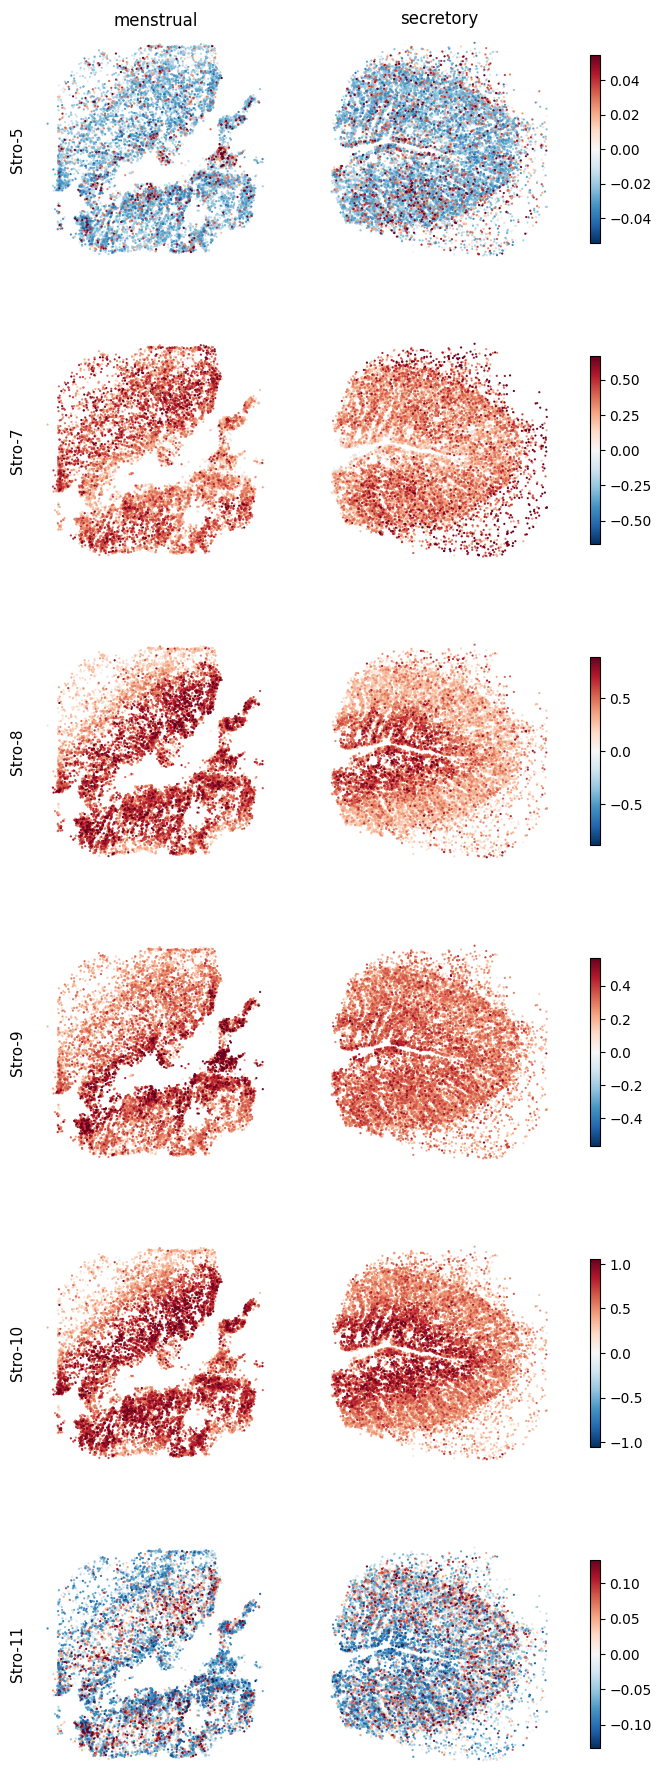

In [16]:
scores = pd.read_csv(OUT / "per_cell_subtype_scores.csv", index_col=0)
score_cols = [c for c in scores.columns if c.startswith("score_")]
tps = sorted(scores["timepoint"].astype(str).unique())

fig, axes = plt.subplots(len(score_cols), len(tps),
                         figsize=(4.2 * len(tps), 3.8 * len(score_cols)), squeeze=False)
for i, col in enumerate(score_cols):
    v = scores[col].to_numpy(float)
    lim = np.nanpercentile(np.abs(v), 99)
    for j, tp in enumerate(tps):
        m = (scores["timepoint"].astype(str) == tp).to_numpy()
        x, y = scores["x_um_dbscan"].to_numpy(float), scores["y_um_dbscan"].to_numpy(float)
        ok = m & np.isfinite(x) & np.isfinite(y)
        o = np.argsort(np.abs(v[ok]))
        ax = axes[i, j]
        p = ax.scatter(x[ok][o], y[ok][o], c=v[ok][o], s=2.5, cmap="RdBu_r",
                       vmin=-lim, vmax=lim, linewidths=0, rasterized=True)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
        if i == 0:
            ax.set_title(tp, fontsize=12)
        if j == 0:
            ax.text(-0.05, .5, col.replace("score_", ""), transform=ax.transAxes,
                    rotation=90, va="center", ha="right", fontsize=11)
    fig.colorbar(p, ax=axes[i, :].tolist(), shrink=.75)
plt.savefig(OUT / "fig5_spatial_scores.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. What to write in the rebuttal

`TABLE_correspondence_summary.csv` is the deliverable. What the analysis found:

**Two confident correspondences.** Stro-7 (C7 fibroblast) → cluster 3 and Stro-10 (dS3) →
cluster 1. Both are reciprocal, score well above the negative-control band, survive gene
bootstrap and held-out-gene validation at 1.00, and reproduce independently in all six
sections. Stro-7 is additionally reciprocal at *every* clustering resolution from 0.3 to
2.0, with the largest margin at each.

**One probable.** Stro-8 (dS1) → cluster 5: reciprocal and bootstrap-stable, but with a
small margin, and Stro-9 (dS2) maps to the same cluster. We recover decidualised stroma but
do not resolve dS1 from dS2. Their defining difference is an immediate-early/stress program
(FOSB, JUND, ATF3, NR4A1), which is a dissociation-associated signature in whole-cell data
and is systematically damped in nuclei — a protocol difference, not a missing population.

**Two with no counterpart, for structural reasons worth stating plainly.** Stro-5 (RUNX3+
fibroblast) is defined by immune genes (GNLY, NKG7, CCL5, PTPRC, TYROBP); our object
excludes immune cells and only ~1% of nuclei carry any of that panel. Stro-11 (stromal
progenitor) is defined by cell-cycle genes (TOP2A, MKI67, UBE2C); only ~3% of our nuclei are
positive for any of them and MKI67 is detected in 0.006%. Neither absence reflects a
limitation of the mapping — a subtype defined by a program that is absent by construction
cannot map, and marker detectability (§6) predicts the calls almost perfectly.

**On C7 expression specifically.** C7 is detected in 0.90% of nuclei object-wide, but is
16.2× enriched in the nominated cluster (6.63% vs 0.41% elsewhere), which holds 58.2% of all
C7+ nuclei while being 7.9% of the object. The centroid mapping nominated that cluster
without reference to C7's sparsity, so low absolute expression is a detection property of
snRNA rather than weak evidence.

**Caveats to state before a reviewer finds them.** Donor and cycle phase are perfectly
confounded (`mck5` menstrual, `mck6` secretory), so six-section replication is replication
across both donors and both phases but cannot separate the two factors. And the raw Spearman
companion disagrees with the headline metric for most subtypes — that is expected across the
single-nucleus/single-cell boundary and is explained in §2, but it should be shown rather
than omitted.

### Next step

`hammoud_fib_mapping.py` is dataset-agnostic. For the XMens arm the only additional piece is
a human→mouse ortholog map on the gene axis (or SAMap-projected labels); that object already
carries `fine_refined` labels, so no clustering step is needed there.